# Clase 7 · Parte 1: un servidor MCP con las series del BCRP

Construí un servidor MCP con **FastMCP 4** que le da a Claude acceso a las 17,167 series oficiales del Banco
Central de Reserva del Perú (BCRP). El código vive en [server.py](server.py) porque Claude Code lo ejecuta como
programa (`uv run server.py`) y las pruebas lo importan; este notebook explica cada parte y la prueba con datos reales.

| Primitiva | Nombre | Para qué |
|---|---|---|
| Herramienta | `buscar_series` | Encontrar el código de una serie por palabras |
| Herramienta | `serie` (TODO 1) | Bajar los datos entre dos fechas, con la URL de la fuente |
| Herramienta | `resumen` (TODO 2) | Variaciones, promedio y extremos calculados en Python, no por el modelo |
| Herramienta | `comparar_paises` (TODO 3, propia) | Comparar al Perú con otros países con datos del Banco Mundial |
| Recurso | `bcrp://serie/{codigo}`, `bcrp://series-clave` (TODO 4) | Fichas que se adjuntan con `@` |
| Prompt | `informe(tema)` (TODO 5) | Receta de informe que se lanza con `/` |

In [1]:
import json

import matplotlib.pyplot as plt
import pandas as pd
from fastmcp import Client
from fastmcp.exceptions import ToolError

import server
from server import mcp

pd.set_option("display.max_colwidth", 90)


async def llamar(herramienta, **args):
    """Llama una herramienta del servidor en memoria, con el mismo protocolo que usa Claude Code."""
    async with Client(mcp) as c:
        return (await c.call_tool(herramienta, args)).data

## 1. El catálogo

La primera llamada baja el catálogo oficial (unos 7 MB) a `datos/`; las siguientes usan esa copia. Cada serie tiene
una frecuencia, y de ella depende el formato de fecha que pide la API.

In [2]:
cat = server.catalogo()
print(f"{len(cat):,} series")
cat.frecuencia.value_counts()

17,167 series


frecuencia
Mensual       8177
Anual         6144
Trimestral    2727
Diaria         119
Name: count, dtype: int64

## 2. Los formatos de fecha de la API (TODO 1)

Lo más delicado del proyecto: la API pide las fechas en un formato y devuelve los periodos en otro.
`_fecha_api` traduce lo que pide Claude a lo que pide la API; si falta el mes o el día, completa con el inicio o el
final del periodo.

In [3]:
pd.DataFrame([
    {"frecuencia": f, "Claude pide": e,
     "API desde": server._fecha_api(e, f, False), "API hasta": server._fecha_api(e, f, True)}
    for f, e in [("Mensual", "2025-01"), ("Mensual", "2025"), ("Diaria", "2026-10-15"),
                 ("Diaria", "2026-10"), ("Trimestral", "2025-T1"), ("Anual", "2025")]
])

,frecuencia,Claude pide,API desde,API hasta
0,Mensual,2025-01,2025-1,2025-1
1,Mensual,2025,2025-1,2025-12
2,Diaria,2026-10-15,2026-10-15,2026-10-15
3,Diaria,2026-10,2026-10-01,2026-10-31
4,Trimestral,2025-T1,2025-1,2025-1
5,Anual,2025,2025,2025


`_periodo` hace el camino inverso. Setiembre puede llegar como `Set` o como `Sep`, y los días y trimestres traen el
año con dos dígitos.

In [4]:
pd.DataFrame([{"la API devuelve": n, "serie devuelve": server._periodo(n)}
              for n in ["Ene.2025", "Set.2026", "Sep.2026", "01.Oct.26", "T1.25", "2025"]])

,la API devuelve,serie devuelve
0,Ene.2025,2025-01
1,Set.2026,2026-09
2,Sep.2026,2026-09
3,01.Oct.26,2026-10-01
4,T1.25,2025-T1
5,2025,2025


## 3. Las herramientas, como las ve Claude

FastMCP convierte cada función en una herramienta: el docstring es la descripción que lee el modelo para decidir
cuándo usarla, y los tipos de los argumentos se vuelven su esquema.

In [5]:
async with Client(mcp) as c:
    herramientas = await c.list_tools()
pd.DataFrame([{"herramienta": t.name, "descripción": t.description.splitlines()[0]} for t in herramientas])

,herramienta,descripción
0,buscar_series,"Busca series del BCRP por palabras: todas deben aparecer en la categoría, el grupo o e..."
1,serie,"Datos de una serie del BCRP entre dos fechas, ambas incluidas."
2,resumen,"Resumen de una serie del BCRP entre dos fechas: primer y último dato, cambio, variació..."
3,comparar_paises,Compara al Perú con otros países con un indicador anual del Banco Mundial.


### buscar_series: primero el código

In [6]:
pd.DataFrame(await llamar("buscar_series", texto="ipc 12 meses", limite=5))

,codigo,nombre,categoria,frecuencia,inicio,actualizada
0,PN01273PM,Índice de precios Lima Metropolitana (var% 12 meses) - IPC,Inflación,Mensual,Ene-1950,2026-10-08
1,PN09821PM,Índice de precios Lima Metropolitana (var% 12 meses) - IPC Importado,Inflación,Mensual,Ene-1992,2026-10-08
2,PN01279PM,Índice de precios Lima Metropolitana (var% 12 meses) - IPC Subyacente,Inflación,Mensual,Ene-1993,2026-10-08
3,PN01281PM,Índice de precios Lima Metropolitana (var% 12 meses) - IPC Transables,Inflación,Mensual,Ene-1993,2026-10-08
4,PN01283PM,Índice de precios Lima Metropolitana (var% 12 meses) - IPC No Transables,Inflación,Mensual,Ene-1993,2026-10-08


### serie: los datos con su fuente (TODO 1)

In [7]:
s = await llamar("serie", codigo="PN01273PM", desde="2025-01", hasta="2026-09")
print(s["nombre"])
print("fuente:", s["fuente"])
inflacion = pd.DataFrame(s["datos"])
inflacion.tail()

Índice de precios Lima Metropolitana (var% 12 meses) - IPC
fuente: https://estadisticas.bcrp.gob.pe/estadisticas/series/api/PN01273PM/json/2025-1/2026-9


,periodo,valor
16,2026-05,3.905052
17,2026-06,4.008910
18,2026-07,4.065153
19,2026-08,4.437809
20,2026-09,4.548655


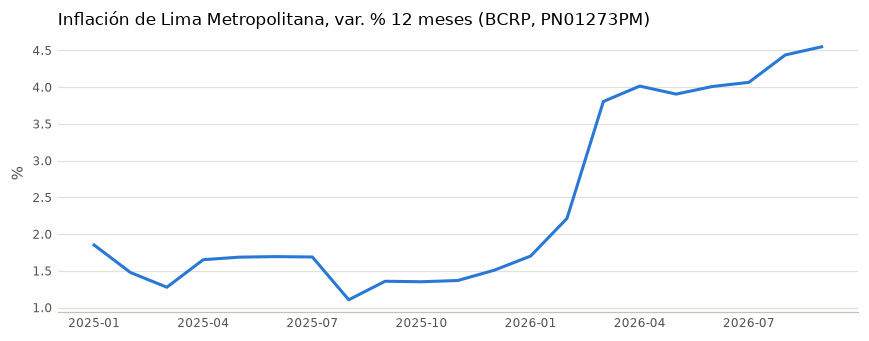

In [8]:
fig, ax = plt.subplots(figsize=(8, 3.2), dpi=110)
ax.plot(inflacion.periodo, inflacion.valor, color="#2a78d6", linewidth=2)
ax.set_title("Inflación de Lima Metropolitana, var. % 12 meses (BCRP, PN01273PM)", loc="left", fontsize=11)
ax.set_xticks(inflacion.periodo[::3])
ax.tick_params(length=0, labelsize=8, colors="#52514e")
ax.yaxis.grid(True, color="#e1e0d9", linewidth=0.8)
ax.set_axisbelow(True)
for lado in ("top", "right", "left"):
    ax.spines[lado].set_visible(False)
ax.spines["bottom"].set_color("#c3c2b7")
ax.set_ylabel("%", color="#52514e")
plt.tight_layout()
plt.show()

### resumen: las cuentas las hace Python (TODO 2)

Así el modelo nunca calcula a mano: pide el resumen y cita lo que devuelve.

In [9]:
r = await llamar("resumen", codigo="PN01273PM", desde="2025-12", hasta="2026-09")
print(json.dumps(r, indent=1, ensure_ascii=False))

{
 "codigo": "PN01273PM",
 "nombre": "Índice de precios Lima Metropolitana (var% 12 meses) - IPC",
 "frecuencia": "Mensual",
 "n": 10,
 "primero": {
  "periodo": "2025-12",
  "valor": 1.5088
 },
 "ultimo": {
  "periodo": "2026-09",
  "valor": 4.5487
 },
 "cambio": 3.0399,
 "variacion_pct": 201.475,
 "promedio": 3.4208,
 "maximo": {
  "periodo": "2026-09",
  "valor": 4.5487
 },
 "minimo": {
  "periodo": "2025-12",
  "valor": 1.5088
 },
 "fuente": "https://estadisticas.bcrp.gob.pe/estadisticas/series/api/PN01273PM/json/2025-12/2026-9"
}


Un código que no existe da un `ToolError` claro, que el modelo puede leer para corregirse y reintentar.

In [10]:
try:
    await llamar("serie", codigo="XX999", desde="2025-01", hasta="2025-02")
except ToolError as e:
    print("ToolError:", e)

[10/28/26 21:30:11] Error calling tool 'serie'

ToolError: No existe el código de serie 'XX999'. Búsquenlo con buscar_series.


### comparar_paises: mi herramienta propia (TODO 3)

El BCRP publica solo cifras del Perú, así que preguntas como «¿creció el Perú más que Chile?» quedaban fuera. Esta
herramienta usa la API del Banco Mundial (sin clave), valida los códigos antes de llamar y devuelve la URL consultada.

In [11]:
c = await llamar("comparar_paises", paises="PER;CHL;COL;MEX;BRA", desde=2016, hasta=2025)
print(c["nombre"])
print("fuente:", c["fuente"])
tabla = pd.DataFrame([{"país": p["pais"], **{d["periodo"]: d["valor"] for d in p["datos"]}, "promedio": p["promedio"]}
                      for p in c["paises"]]).set_index("país")
tabla.round(1).sort_values("promedio", ascending=False)

GDP growth (annual %)
fuente: https://api.worldbank.org/v2/country/PER;CHL;COL;MEX;BRA/indicator/NY.GDP.MKTP.KD.ZG?format=json&date=2016:2025&per_page=2000


,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,promedio
país,,,,,,,,,,,
Colombia,2.1,1.4,2.6,3.2,-7.2,10.8,7.3,0.8,1.5,2.6,2.5
Peru,4.0,2.5,4.0,2.2,-10.9,13.4,2.8,-0.4,3.5,3.4,2.5
Chile,1.8,1.4,4.0,0.6,-6.1,11.3,2.1,0.7,2.8,2.5,2.1
Brazil,-3.3,1.3,1.8,1.2,-3.3,4.8,3.0,3.2,3.4,2.3,1.5
Mexico,1.8,1.9,2.0,-0.4,-8.4,6.0,3.7,3.1,1.4,0.6,1.2


## 4. Recurso y prompt (TODO 4 y 5)

Las herramientas las elige el modelo; los recursos y los prompts los elige uno. En Claude Code el recurso se adjunta
con `@bcrp:bcrp://serie/PN01273PM` y el prompt se lanza con `/mcp__bcrp__informe inflación`.

In [12]:
async with Client(mcp) as c:
    print("plantillas:", [t.uri_template for t in await c.list_resource_templates()])
    print("recursos:  ", [str(x.uri) for x in await c.list_resources()])
    print("\nficha:", (await c.read_resource("bcrp://serie/PN01273PM"))[0].text)
    print("\nprompt:", (await c.get_prompt("informe", {"tema": "inflación"})).messages[0].content.text)

plantillas: ['bcrp://serie/{codigo}']
recursos:   ['bcrp://series-clave']

ficha: {"codigo": "PN01273PM", "nombre": "Índice de precios Lima Metropolitana (var% 12 meses) - IPC", "categoria": "Inflación", "frecuencia": "Mensual", "inicio": "Ene-1950", "actualizada": "2026-10-08"}

prompt: Escribe un informe de 5 viñetas sobre «inflación» con datos oficiales del BCRP. Primero busca los códigos con buscar_series; para cada cifra usa resumen o serie, nunca calcules a mano. En cada viñeta cita el código de la serie, el periodo y la URL de la fuente. Si hace falta contexto internacional, usa comparar_paises. Si una cifra no está disponible, dilo en vez de estimarla.


## 5. Las 8 pruebas

[test_server.py](test_server.py) es el contrato del curso (sin cambios): si pasan, Claude Code y la evaluación pueden
usar el servidor.

In [13]:
import sys

!{sys.executable} -m pytest -q

........                                                                 [100%]
8 passed in 6.13s


## 6. Conectarlo a Claude Code

[.mcp.json](.mcp.json) registra el servidor `bcrp` y el de `fetch`, sin claves. Se creó con
`claude mcp add --scope project bcrp -- uv run server.py` y `claude mcp add --scope project fetch -- uvx mcp-server-fetch`.
Al abrir `claude` en esta carpeta se aprueban una vez y `/mcp` los muestra conectados.

In [14]:
print(open(".mcp.json", encoding="utf-8").read())

{
  "mcpServers": {
    "bcrp": {
      "type": "stdio",
      "command": "uv",
      "args": ["run", "server.py"],
      "env": {}
    },
    "fetch": {
      "type": "stdio",
      "command": "uvx",
      "args": ["mcp-server-fetch"],
      "env": {}
    }
  }
}

